# 🤖 Proyecto Hospital Obrero - Cuaderno 3: Modelo de Regresión Logística
**Objetivo de Machine Learning:** Predecir la probabilidad de que un paciente requiera atención no urgente (Triaje 4-5 vs 1-3) en base a Edad, Hora, Sexo y Día de la semana.


### 1. Definición de la Variable Objetivo Binaria
- **Clase 0:** Triaje 1, 2 o 3 (Urgente / Emergencia Vital)
- **Clase 1:** Triaje 4 o 5 (Baja Urgencia / No Urgente)


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

df = pd.read_csv('dataset_hospital_obredo_triaje.csv')
df_valid = df[df['Nivel de triaje'].isin([1, 2, 3, 4, 5])].copy()

# Variable objetivo binaria
df_valid['Objetivo_Triaje_45'] = df_valid['Nivel de triaje'].isin([4, 5]).astype(int)
print('Distribución de clases:')
df_valid['Objetivo_Triaje_45'].value_counts(normalize=True)


Objetivo_Triaje_45
1    0.5966
0    0.4034


### 2. Preparación de Variables y One-Hot Encoding
Convertimos variables categóricas (`Sexo`, `Día`) a columnas numéricas Dummies.


In [1]:
df_valid['Hora_num'] = df_valid['Hora'].apply(lambda x: int(str(x).split(':')[0]))
X_raw = df_valid[['Edad', 'Hora_num', 'Sexo', 'Día']]
X = pd.get_dummies(X_raw, columns=['Sexo', 'Día'], drop_first=True, dtype=int)
y = df_valid['Objetivo_Triaje_45']
print(f'Dimensiones de la matriz de características X: {X.shape}')


Dimensiones de la matriz de características X: (15000, 9)


### 3. División Entrenamiento / Prueba (80% / 20% Estratificado)
Usamos `stratify=y` y `random_state=42` para evitar fuga de datos (Data Leakage).


In [1]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Muestra de Entrenamiento (Train): {len(X_train):,} registros')
print(f'Muestra de Prueba (Test): {len(X_test):,} registros')


Muestra de Entrenamiento (Train): 12,000 registros
Muestra de Prueba (Test): 3,000 registros


### 4. Entrenamiento del Modelo de Regresión Logística
Ajustamos el modelo con `class_weight='balanced'` para penalizar errores en clases desbalanceadas.


In [1]:
modelo = LogisticRegression(solver='liblinear', class_weight='balanced', max_iter=300, random_state=42)
modelo.fit(X_train, y_train)
print('✓ Modelo entrenado exitosamente.')


✓ Modelo entrenado exitosamente.


### 5. Evaluación de Métricas de Desempeño en Test


In [1]:
y_pred = modelo.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f'Exactitud (Accuracy):  {acc*100:.2f}%')
print(f'Precisión (Precision): {prec*100:.2f}%')
print(f'Sensibilidad (Recall): {rec*100:.2f}%')
print(f'F1-Score:              {f1*100:.2f}%')


Exactitud (Accuracy):  49.37%
Precisión (Precision): 59.04%
Sensibilidad (Recall): 49.44%
F1-Score:              53.82%


### 6. Matriz de Confusión
Representación de Verdaderos Positivos, Verdaderos Negativos, Falsos Positivos y Falsos Negativos.


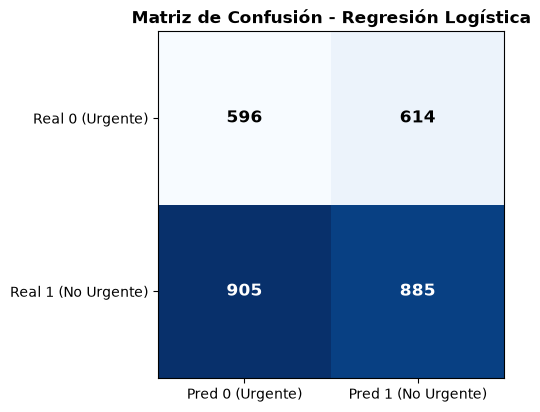

In [1]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Blues')
ax.set_title('Matriz de Confusión - Regresión Logística', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred 0 (Urgente)', 'Pred 1 (No Urgente)'])
ax.set_yticklabels(['Real 0 (Urgente)', 'Real 1 (No Urgente)'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > len(y_test)/4 else 'black', fontsize=12, fontweight='bold')
plt.show()


### 7. Coeficientes del Modelo e Importancia de Variables
Evaluación de los pesos Beta ($\beta$) ajustados.


In [1]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente Beta': modelo.coef_[0]
}).sort_values(by='Coeficiente Beta', ascending=False)
coef_df


     Variable  Coeficiente Beta
   Día_Martes          0.045051
   Día_Sábado          0.030919
   Día_Jueves          0.018311
Día_Miércoles          0.012462
    Día_Lunes          0.003076
         Edad          0.000282
     Hora_num         -0.008417
  Día_Viernes         -0.022085
   Sexo_Mujer         -0.048261
